# Forecasting the next trading session’s close

Can Ridge, XGBoost, or an LSTM improve on carrying forward today’s adjusted closing price? This notebook pools five U.S. stocks, tunes on 2020–2022, and scores frozen models on the 2023–2025 holdout. The [README](README.md) describes setup and the exported files.

In [1]:
import json
import os
from importlib.metadata import version
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import forecasting as fc

fc.configure_cpu()
snapshot = Path("data/yahoo_2010_2025.csv")
output = Path(os.environ.get("STOCK_FORECAST_OUTPUT", "outputs"))
output.mkdir(parents=True, exist_ok=True)

## Prepare one-session forecasts

Each sample contains the 20 most recent trading sessions ending at its forecast origin. Each session contributes one- and five-session log returns, the previous 20 returns’ standard deviation, the log high/low and close/open ratios, and log volume relative to its trailing 20-session median. All rolling windows include the current bar. The next exchange session’s log return is the target, expressed in basis points. Prices use Yahoo Finance’s split- and dividend-adjusted basis.

In [2]:
bars = fc.load_snapshot(snapshot)
sessions = fc.exchange_sessions()
samples = fc.build_samples(bars, sessions)
fc.check_alignment(bars, sessions, samples)

labeled = samples.select(samples.rows["actual_return_bps"].notna())
years = labeled.rows["target_date"].dt.year
development = labeled.select(years < fc.TEST_YEAR)
holdout = labeled.select(years >= fc.TEST_YEAR)
assert development.rows["target_date"].max() <= holdout.rows["origin"].min()

provenance = fc.snapshot_metadata(snapshot, bars)
display(pd.Series(provenance, name="Data snapshot").to_frame())
display(pd.Series({"Development rows": len(development.rows), "Holdout rows": len(holdout.rows)}))

,Data snapshot
source,Yahoo Finance historical pages (embedded daily...
retrieved_at_utc,2026-11-22T17:38:53.871729+00:00
sha256,a63a521b12b2a91478f961e01b612570887f7705d43a7a...
first_bar,2010-01-04
last_bar,2025-12-31
rows,20120


Development rows    16160
Holdout rows         3760
dtype: int64

## Select settings using development data

For each validation year, train on earlier target years and score the following year. The first forecast of each validation year can use its origin session’s close, including labels already observed at that close. Choose settings by the mean of the three validation MAEs. Ridge and XGBoost see the same window flattened across time, while the LSTM sees the ordered sequence. Ridge scales each lagged input and the LSTM scales each feature across positions. Both scalers are fit inside each training fold.

In [3]:
selected, validation = fc.select_settings(development)
fitted = {name: fc.fit_model(name, settings, development) for name, settings in selected.items()}
display(pd.Series({name: json.dumps(settings) for name, settings in selected.items()},
                  name="Selected settings").to_frame())

,Selected settings
Ridge,"{""alpha"": 1000}"
XGBoost,"{""max_depth"": 2, ""n_estimators"": 100}"
LSTM,"{""hidden_size"": 16, ""epochs"": 8}"


## Evaluate the 2023–2025 holdout

Return MAE is the primary measure. Return RMSE gives larger misses more weight. Adjusted-price MAE in dollars is calculated within each stock. Directional accuracy only includes realized up and down sessions. The majority direction is chosen from the development period and then evaluated on the holdout. The no-change forecast has zero predicted direction, so its directional accuracy is blank. Negative MAE change means improvement over no change.

In [4]:
predicted = fc.forecast(holdout, fitted)
fc.check_predictions(predicted, holdout)
predicted["target_year"] = predicted["target_date"].dt.year
majority_direction = 1 if (development.returns > 0).sum() >= (development.returns < 0).sum() else -1
overall = fc.score(predicted, majority_direction).sort_values("mae_bps")
by_stock = fc.score(predicted, majority_direction, "ticker")
by_year = fc.score(predicted, majority_direction, "target_year")
display(overall.round(4))
display(by_stock.pivot(index="ticker", columns="model", values="mae_bps").round(2))

,model,n,mae_bps,rmse_bps,direction_n,direction_accuracy,training_majority_accuracy,mae_change_vs_no_change_pct
2,XGBoost,3760,95.5625,137.1693,3750,0.5429,0.5448,-0.5710
3,LSTM,3760,95.8781,137.4620,3750,0.5200,0.5448,-0.2426
0,No change,3760,96.1112,137.8894,3750,NaN,0.5448,0.0000
1,Ridge,3760,96.8368,138.3077,3750,0.5061,0.5448,0.7550


model,LSTM,No change,Ridge,XGBoost
ticker,,,,
AAPL,110.02,110.11,111.21,109.38
JNJ,75.98,76.04,77.46,75.89
JPM,99.09,99.74,98.87,98.71
WMT,85.91,86.28,87.28,85.66
XOM,108.39,108.37,109.37,108.18


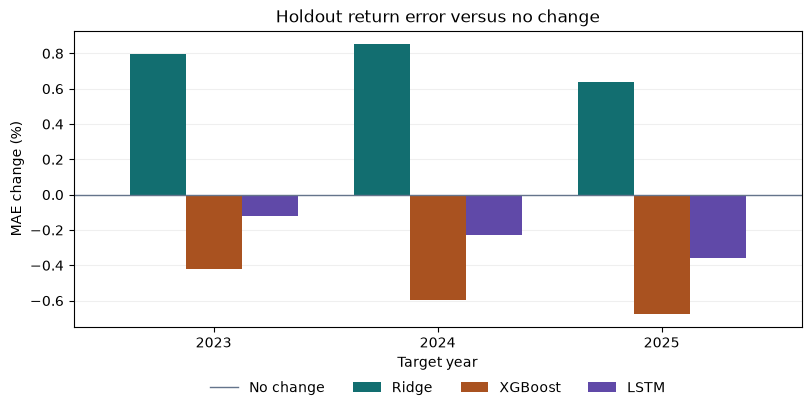

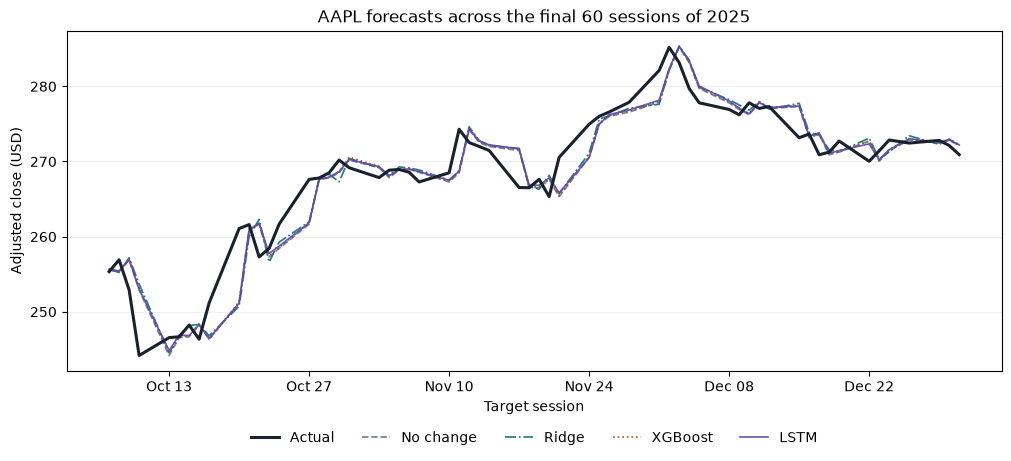

In [5]:
colors = {"No change": "#64748b", "Ridge": "#126e70", "XGBoost": "#a95220", "LSTM": "#6049a8"}
learned = list(fc.MODEL_SETTINGS)
comparison = by_year.pivot(index="target_year", columns="model", values="mae_change_vs_no_change_pct")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
comparison[learned].plot.bar(ax=ax, color=[colors[name] for name in learned], width=0.75)
ax.axhline(0, color=colors[fc.NO_CHANGE], linewidth=1, label="No change")
ax.set(title="Holdout return error versus no change", xlabel="Target year", ylabel="MAE change (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.savefig(output / "error_by_year.png", dpi=180)
plt.show()

apple = predicted.loc[predicted["ticker"].eq("AAPL")]
last_dates = apple["target_date"].drop_duplicates().tail(60)
recent = apple.loc[apple["target_date"].isin(last_dates)]
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
observed = recent.drop_duplicates("target_date")
ax.plot(observed["target_date"], observed["actual_adjusted_close"], color="#18212c",
        linewidth=2.2, label="Actual", zorder=4)
for name, style in zip(fc.MODELS, ("--", "-.", ":", "-")):
    group = recent.loc[recent["model"].eq(name)]
    ax.plot(group["target_date"], group["predicted_adjusted_close"], color=colors[name],
            linewidth=1.25, linestyle=style, label=name, alpha=0.9)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(title="AAPL forecasts across the final 60 sessions of 2025",
       xlabel="Target session", ylabel="Adjusted close (USD)")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.savefig(output / "aapl_price_forecasts.png", dpi=180)
plt.show()

## Export the results and make one additional forecast

Use the final snapshot close to forecast the following exchange session. That session’s actual close is outside the snapshot, so this example is excluded from every experimental score.

In [6]:
latest = samples.select(samples.rows["origin"].eq(bars["date"].max()))
assert len(latest.rows) == len(fc.TICKERS) and latest.rows["actual_return_bps"].isna().all()
next_forecast = fc.forecast(latest, fitted).drop(columns=["actual_adjusted_close", "actual_return_bps"])
tables = {"metrics_overall": overall, "metrics_by_stock": by_stock, "metrics_by_year": by_year,
          "holdout_predictions": predicted, "validation_scores": validation, "next_forecast": next_forecast}
for filename, table in tables.items():
    table.to_csv(output / f"{filename}.csv", index=False, float_format="%.12g")

packages = ("numpy", "pandas", "scikit-learn", "xgboost", "torch", "exchange-calendars", "matplotlib")
experiment = {"snapshot": provenance, "packages": {package: version(package) for package in packages},
              "seed": fc.SEED, "selected_settings": selected, "majority_direction": majority_direction,
              "validation_years": fc.VALIDATION_YEARS, "holdout_start_year": fc.TEST_YEAR}
(output / "experiment.json").write_text(json.dumps(experiment, indent=2) + "\n")
display(next_forecast.pivot(index="ticker", columns="model", values="predicted_adjusted_close").round(2))

model,LSTM,No change,Ridge,XGBoost
ticker,,,,
AAPL,270.97,270.92,270.53,271.06
JNJ,203.64,203.67,203.87,203.78
JPM,316.15,316.13,316.16,316.30
WMT,110.71,110.71,110.83,110.77
XOM,117.27,117.23,117.35,117.30
